In [1]:
import pandas as pd
from analyze import load_results, merge_length_groups, build_model_summary, display_summary_tables, radar_chart

# Bu listedeki modeller tum tablo ve ozetlerden tamamen dislanir.
ignore_results = [
    "cosyvoice_paris", "omnivoice", "voxcpm_trendyol", "cosyvoice",
]

# Tablolarda/model etiketlerinde gorunsun istedigin isimler.
name_map = {
    'chatterbox_zs': "Chatterbox Zero-Shot",
    'cosyvoice_raw': "Cosyvoice",
    # 'cosyvoice': "Cosyvoice - Raw Text",
    # 'cosyvoice_raw': "Cosyvoice - Phonemes",
    'omnivoice_raw': "Omnivoice",
    'omnivoice_zs': "Omnivoice Zero-Shot",
    'vits': "VITS",
    'voxcpm2_zs': "VoxCPM2 Zero-Shot",
    # 'voxcpm_trendyol': "VoxCPM Trendyol Zero-Shot",
}


def map_model_name(model_name: str) -> str:
    return name_map.get(model_name, model_name)

In [4]:
test_path        = "/mnt/local3/tts/tts_evaluation/data/tts_evaluation_test.csv"
wer_results_path = "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_wer_average.csv"
result_path_list = [
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_1.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_2.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_3.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_4.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_5.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_6.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_7.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_8.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_9.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_10.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_11.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_12.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_13.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_14.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_15.csv",
    # "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_detailed_16.csv",
    "/mnt/local3/tts/tts_evaluation/evaluation_tool/results_gozde_detailed.csv",
]

results_df, test_df, model2ttsds, model2wer = load_results(result_path_list, wer_results_path, test_path)
results_df

,File,Input,audiobox_pq,brouhaha,dnsmos_pro,utmos_v2,whisqa
0,/mnt/local3/tts/tts_evaluation/data/gozde/dial...,dialogue,7.587684,67.768730,3.409124,3.683594,4.291149
1,/mnt/local3/tts/tts_evaluation/data/gozde/dial...,dialogue,7.865109,68.531082,3.744283,3.859375,4.837106
2,/mnt/local3/tts/tts_evaluation/data/gozde/dial...,dialogue,7.850982,56.167709,3.562662,3.474609,4.753134
3,/mnt/local3/tts/tts_evaluation/data/gozde/dial...,dialogue,7.957860,59.608822,3.835701,3.345703,4.718876
4,/mnt/local3/tts/tts_evaluation/data/gozde/dial...,dialogue,7.917524,65.611252,3.792790,3.599609,4.901669
...,...,...,...,...,...,...,...
1459,/mnt/local3/tts/tts_evaluation/data/gozde/scri...,script,7.609390,59.433327,3.493075,3.816406,4.619950
1460,/mnt/local3/tts/tts_evaluation/data/gozde/scri...,script,7.661174,56.687386,3.564019,2.890625,4.691314
1461,/mnt/local3/tts/tts_evaluation/data/gozde/scri...,script,7.520412,63.521370,3.476618,3.703125,4.499440
1462,/mnt/local3/tts/tts_evaluation/data/gozde/scri...,script,7.617999,62.258324,3.767370,3.689453,4.813524


In [6]:
# Filtreli dikey-renkli tabloda gösterilecek modeller (kismi esleme, bos = hepsi)
show_results = ["cosyvoice_raw", "omnivoice_raw", "vits"]

In [10]:
grouped_df = merge_length_groups(results_df, test_df)

# ignore_results filtrelemesi
if ignore_results:
    grouped_df = grouped_df[~grouped_df["Input"].isin(ignore_results)].copy()

model_summary, score_cols, num_cols = build_model_summary(grouped_df, model2ttsds, model2wer)

# print edilen tablolarda isimleri daha okunur hale getir
show_results_filtered = [m for m in show_results if m not in ignore_results]
show_results_print = [map_model_name(m) for m in show_results_filtered]

grouped_df_print = grouped_df.copy()
model_summary_print = model_summary.copy()
grouped_df_print["Input"] = grouped_df_print["Input"].map(map_model_name)
model_summary_print["Input"] = model_summary_print["Input"].map(map_model_name)

a = display_summary_tables(
    grouped_df_print,
    model_summary_print,
    score_cols,
    num_cols,
    show_results=show_results_print,
)

Secilen esleme: test_df[path] <-> results_df[File] | eslesen: 882

Model (Input) dagilimi:
Input
script      1075
dialogue     389
Name: count, dtype: int64

Length + Model bazinda sayisal ortalamalar:


,length_group,Input,audiobox_pq,brouhaha,dnsmos_pro,utmos_v2,whisqa
0,long,dialogue,7.590699,58.930932,3.566744,3.281827,4.314733
1,long,script,7.286495,53.376221,3.466764,3.269110,4.240397
2,medium,dialogue,7.558289,59.300675,3.604927,3.246699,4.327464
3,medium,script,7.199960,52.435412,3.469326,3.271426,4.181835
4,short,dialogue,7.772814,59.670080,3.617937,3.323775,4.316355
5,short,script,7.071491,51.437952,3.436499,3.281853,4.136149



Model bazinda sayisal ortalamalar (length_group kirilimi olmadan):
En iyi model (overall_score, gold haric): dialogue


,Input,audiobox_pq,brouhaha,dnsmos_pro,utmos_v2,whisqa,ttsds,wer,overall_score
0,dialogue,7.642648,59.434334,3.597658,3.290945,4.330236,nan,nan,1.0000
1,script,7.121133,51.812642,3.448693,3.271820,4.171503,nan,nan,0.0000



Tum modeller ozeti (sutun en iyileri yesil, gold haric):


,Input,audiobox_pq,brouhaha,dnsmos_pro,utmos_v2,whisqa,ttsds,wer,overall_score
0,dialogue,7.642648,59.434334,3.597658,3.290945,4.330236,nan,nan,1.0000
1,script,7.121133,51.812642,3.448693,3.271820,4.171503,nan,nan,0.0000



Model bazinda sayisal ortalamalar (renksiz):


,Input,audiobox_pq,brouhaha,dnsmos_pro,utmos_v2,whisqa,ttsds,wer,overall_score
0,dialogue,7.642648,59.434334,3.597658,3.290945,4.330236,NaN,NaN,1.0
1,script,7.121133,51.812642,3.448693,3.271820,4.171503,NaN,NaN,0.0



Model bazinda sayisal ortalamalar (dikey, 4 ondalik):


Input,dialogue,script
audiobox_pq,7.642600,7.121100
brouhaha,59.434300,51.812600
dnsmos_pro,3.597700,3.448700
utmos_v2,3.290900,3.271800
whisqa,4.330200,4.171500
ttsds,nan,nan
wer,nan,nan
overall_score,1.000000,0.000000



show_results ile eslesen model bulunamadi.


In [ ]:
a = a.dropna()
a

Input,dialogue,script
audiobox_pq,7.6426,7.1211
brouhaha,59.4343,51.8126
dnsmos_pro,3.5977,3.4487
utmos_v2,3.2909,3.2718
whisqa,4.3302,4.1715
overall_score,1.0000,0.0000


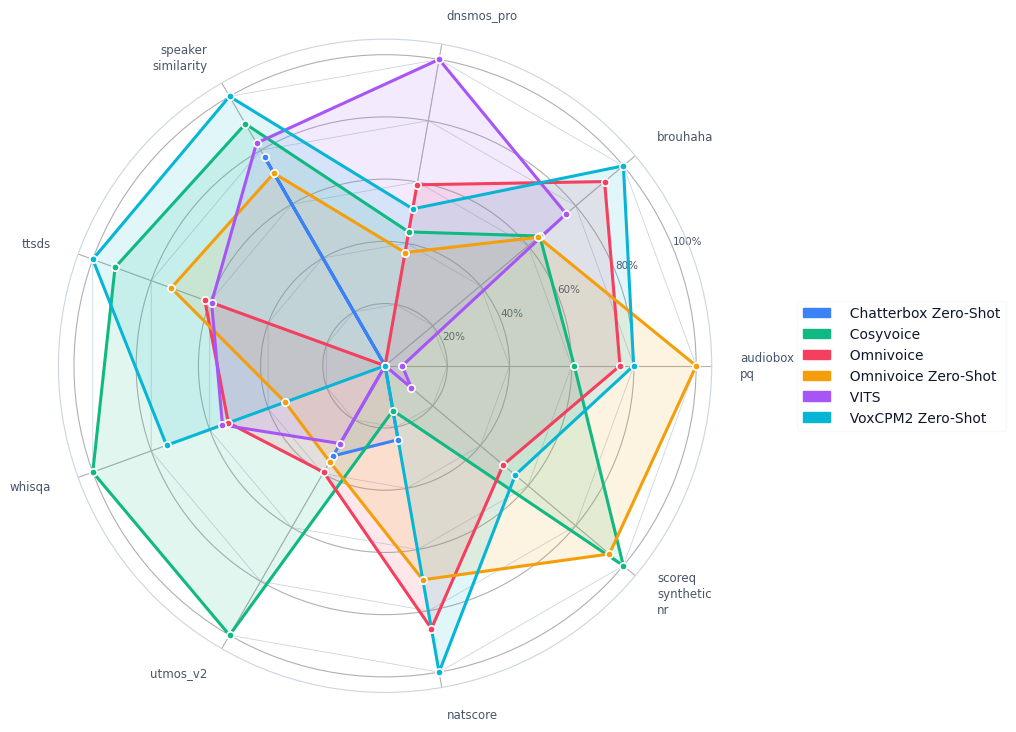

Grafik 'tts_radar_chart.png' olarak kaydedildi.


In [5]:
radar_models = ["cosyvoice_raw", "omnivoice_raw", "vits"]
radar_models = name_map.keys()
radar_models = [m for m in radar_models if m not in ignore_results]

radar_metrics = [
    "audiobox_pq",
    "brouhaha",
    "dnsmos_pro",
    "speaker_similarity",
    "ttsds",
    "whisqa",
    "utmos_v2",
    "natscore",
    "scoreq_synthetic_nr",
    # "wer",
]

radar_chart(model_summary, radar_models, radar_metrics, name_map=name_map)

## Temporal Results

Bu bolum, `evaluation_tool/yunusemre/temporal_outputs` altindaki temporal ciktilari topluca okur ve model bazli ozetler.

In [6]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TEMPORAL_DIR = Path("/mnt/local3/tts/tts_evaluation/evaluation_tool/yunusemre/temporal_outputs")

if not TEMPORAL_DIR.exists():
    raise FileNotFoundError(f"Temporal output klasoru bulunamadi: {TEMPORAL_DIR}")


def _load_temporal_group(prefix: str) -> pd.DataFrame:
    model_summary_files = sorted(TEMPORAL_DIR.glob(f"{prefix}*model_summary.csv"))
    partial_model_summary_files = sorted(TEMPORAL_DIR.glob(f"{prefix}*partial_model_summary.csv"))
    all_model_summary_files = sorted(set(model_summary_files + partial_model_summary_files))

    if not all_model_summary_files:
        raise FileNotFoundError(
            f"{prefix} icin model summary dosyasi bulunamadi: {TEMPORAL_DIR}"
        )

    frames = []
    for path in all_model_summary_files:
        df_tmp = pd.read_csv(path)
        df_tmp["source_file"] = path.name
        df_tmp["is_partial"] = "_partial_" in path.name
        frames.append(df_tmp)

    temporal_df = pd.concat(frames, ignore_index=True)

    if ignore_results:
        temporal_df = temporal_df[
            ~temporal_df["model"].isin(ignore_results)
        ].copy()

    temporal_df["model_print"] = temporal_df["model"].map(map_model_name)
    return temporal_df


def render_temporal_summary_plots(temporal_df: pd.DataFrame, label: str):
    metric_candidates = [
        "mean_sim_vs_ref",
        "mean_utmos_mean",
        "consistency_std_mean",
        "drift_slope_mean",
        "gold_drift_slope_mean",
        "first_last_delta_mean",
        "mean_delta_vs_gold_mean",
    ]

    available_metric_cols = [c for c in metric_candidates if c in temporal_df.columns]
    if not available_metric_cols:
        print(f"{label}: gorsellestirilecek metrik bulunamadi.")
        return None

    temporal_latest_source = temporal_df["source_file"].iloc[-1]
    temporal_latest = temporal_df[
        temporal_df["source_file"] == temporal_latest_source
    ].copy()

    temporal_latest_sorted = temporal_latest.sort_values("model_print")
    temporal_latest_sorted["_vits_first"] = (temporal_latest_sorted["model_print"] != "VITS").astype(int)
    temporal_latest_sorted = temporal_latest_sorted.sort_values(["_vits_first", "model_print"]).drop(columns=["_vits_first"])

    print(f"\n=== {label.upper()} temporal source: {temporal_latest_source} ===")
    display(temporal_latest_sorted[["model_print", *available_metric_cols]].round(4))

    ax = temporal_latest_sorted.set_index("model_print")[available_metric_cols].plot(
        kind="bar",
        figsize=(12, 5),
        rot=20,
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("Value")
    ax.grid(True, axis="y", alpha=0.3)
    for spine in ax.spines.values():
        spine.set_visible(False)

    n_metrics = len(available_metric_cols)
    ncols = min(3, n_metrics)
    nrows = math.ceil(n_metrics / ncols)
    last_row_count = n_metrics - (nrows - 1) * ncols if nrows > 1 else ncols

    fig = plt.figure(figsize=(5 * ncols, 3.6 * nrows))
    outer = fig.add_gridspec(nrows=nrows, ncols=1)

    metric_idx = 0
    for row in range(nrows):
        cols_this_row = ncols if row < (nrows - 1) else last_row_count
        row_gs = outer[row].subgridspec(1, cols_this_row)

        for col in range(cols_this_row):
            metric = available_metric_cols[metric_idx]
            ax_i = fig.add_subplot(row_gs[0, col])
            temporal_latest_sorted.plot(
                kind="bar",
                x="model_print",
                y=metric,
                legend=False,
                ax=ax_i,
                color="#4C78A8",
            )
            ax_i.set_title(metric)
            ax_i.set_xlabel("")
            ax_i.set_ylabel("Value")
            ax_i.grid(True, axis="y", alpha=0.3)
            ax_i.tick_params(axis="x", rotation=20)
            for spine in ax_i.spines.values():
                spine.set_visible(False)

            metric_idx += 1

    fig.tight_layout()

    label_l = label.lower()
    if "utmos_fixed" in label_l and "mean_utmos_mean" in available_metric_cols:
        primary_cols = ["mean_utmos_mean"]
        secondary_cols = [c for c in available_metric_cols if c not in primary_cols]
        primary_ylabel = "UTMOS Mean"
    else:
        primary_cols = [c for c in available_metric_cols if "sim" in c.lower()]
        secondary_cols = [c for c in available_metric_cols if c not in primary_cols]
        primary_ylabel = "Similarity Score"

    if primary_cols:
        ax_primary = temporal_latest_sorted.set_index("model_print")[primary_cols].plot(
            kind="bar",
            figsize=(12, 4),
            rot=20,
        )
        ax_primary.set_xlabel("Model")
        ax_primary.set_ylabel(primary_ylabel)
        ax_primary.grid(True, axis="y", alpha=0.3)
        for spine in ax_primary.spines.values():
            spine.set_visible(False)

    if secondary_cols:
        ax_secondary = temporal_latest_sorted.set_index("model_print")[secondary_cols].plot(
            kind="bar",
            figsize=(12, 4),
            rot=20,
        )
        ax_secondary.set_xlabel("Model")
        ax_secondary.set_ylabel("Value")
        ax_secondary.grid(True, axis="y", alpha=0.3)
        for spine in ax_secondary.spines.values():
            spine.set_visible(False)

    return ax


temporal_fixed_all = _load_temporal_group("fixed_")
temporal_utmos_fixed_all = _load_temporal_group("utmos_fixed_")

display(
    pd.DataFrame(
        {
            "fixed_temporal_files": sorted(temporal_fixed_all["source_file"].unique()),
            "utmos_fixed_temporal_files": sorted(temporal_utmos_fixed_all["source_file"].unique()),
        }
    )
)
temporal_fixed_all.head()

,fixed_temporal_files,utmos_fixed_temporal_files
0,fixed_w2p0s_h1p0s_partial_model_summary.csv,utmos_fixed_w2p0s_h1p0s_partial_model_summary.csv


,model,n_utterances,mean_n_chunks,mean_sim_vs_ref,drift_slope_mean,drift_slope_std,gold_drift_slope_mean,consistency_std_mean,first_last_delta_mean,source_file,is_partial,model_print
0,chatterbox_zs,100.0,12.08,0.830857,-0.039137,0.072473,-0.027864,0.032487,-0.061287,fixed_w2p0s_h1p0s_partial_model_summary.csv,True,Chatterbox Zero-Shot
3,cosyvoice_raw,100.0,11.14,0.852864,-0.009833,0.035714,-0.005847,0.022075,-0.013525,fixed_w2p0s_h1p0s_partial_model_summary.csv,True,Cosyvoice
5,omnivoice_raw,100.0,11.73,0.805437,-0.032889,0.042681,-0.034049,0.033612,-0.050488,fixed_w2p0s_h1p0s_partial_model_summary.csv,True,Omnivoice
6,omnivoice_zs,100.0,11.88,0.819117,-0.018448,0.046485,-0.011008,0.028181,-0.027610,fixed_w2p0s_h1p0s_partial_model_summary.csv,True,Omnivoice Zero-Shot
7,vits,100.0,10.42,0.854480,-0.012539,0.038314,-0.020712,0.022564,-0.017508,fixed_w2p0s_h1p0s_partial_model_summary.csv,True,VITS



=== FIXED temporal source: fixed_w2p0s_h1p0s_partial_model_summary.csv ===


,model_print,mean_sim_vs_ref,consistency_std_mean,drift_slope_mean,gold_drift_slope_mean,first_last_delta_mean
7,VITS,0.8545,0.0226,-0.0125,-0.0207,-0.0175
0,Chatterbox Zero-Shot,0.8309,0.0325,-0.0391,-0.0279,-0.0613
3,Cosyvoice,0.8529,0.0221,-0.0098,-0.0058,-0.0135
5,Omnivoice,0.8054,0.0336,-0.0329,-0.0340,-0.0505
6,Omnivoice Zero-Shot,0.8191,0.0282,-0.0184,-0.0110,-0.0276
8,VoxCPM2 Zero-Shot,0.8493,0.0233,-0.0115,0.0049,-0.0003


<Axes: xlabel='Model', ylabel='Value'>

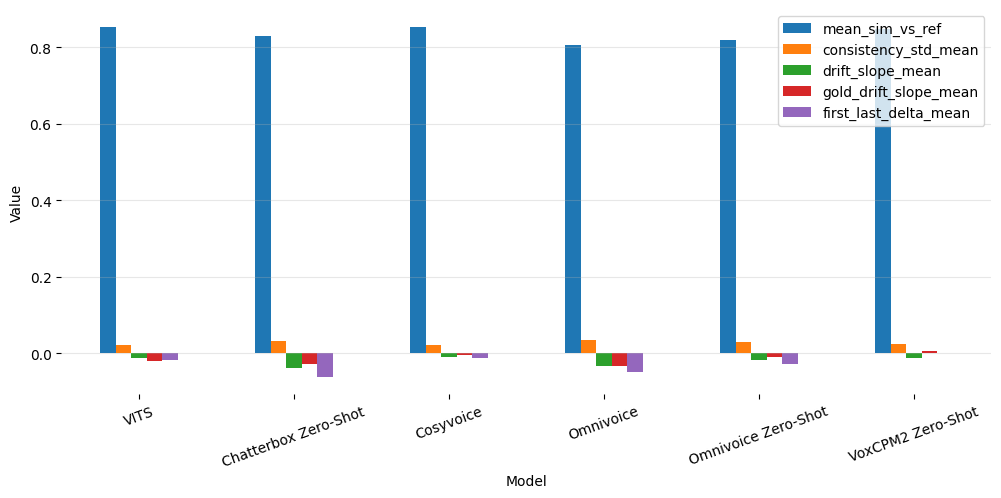

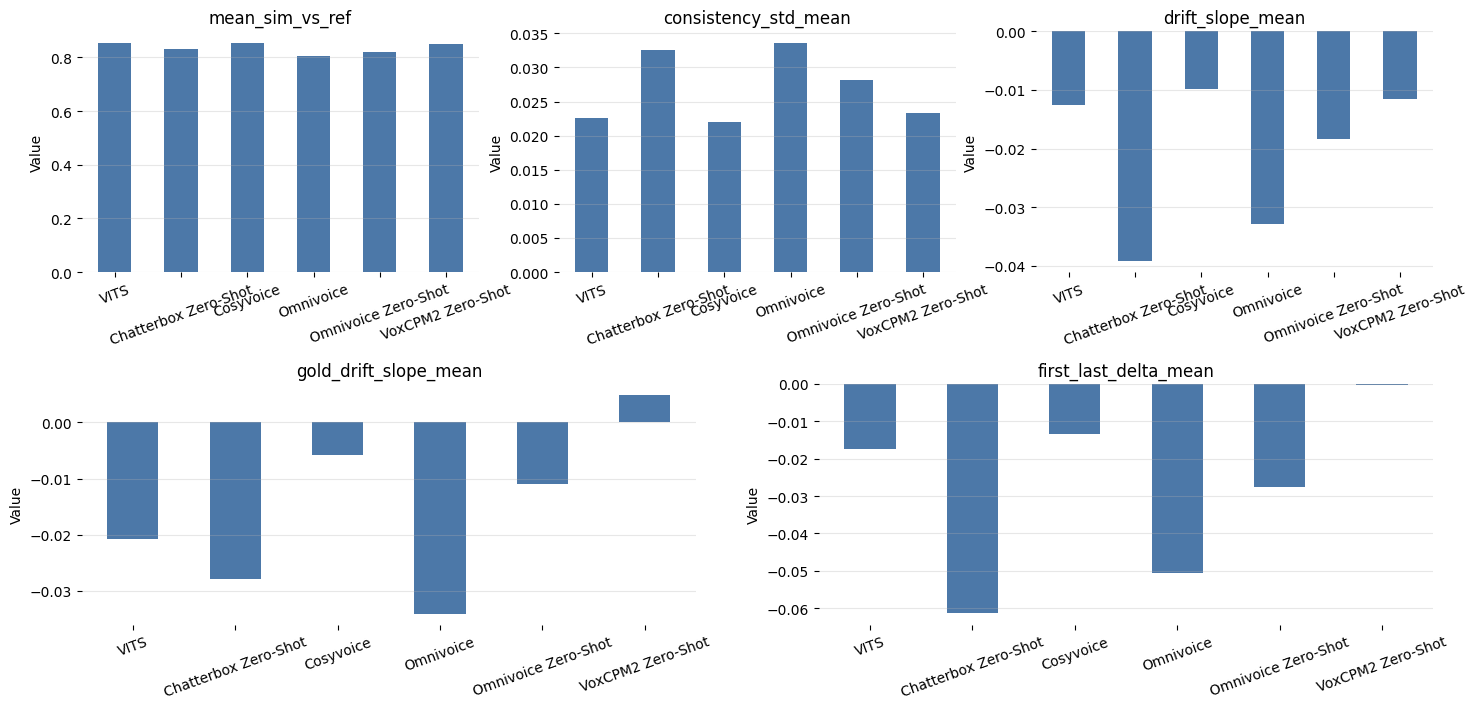

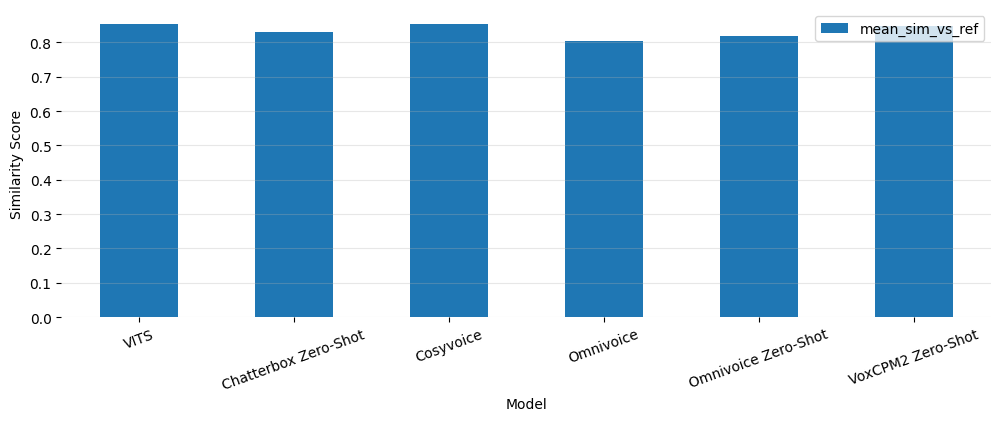

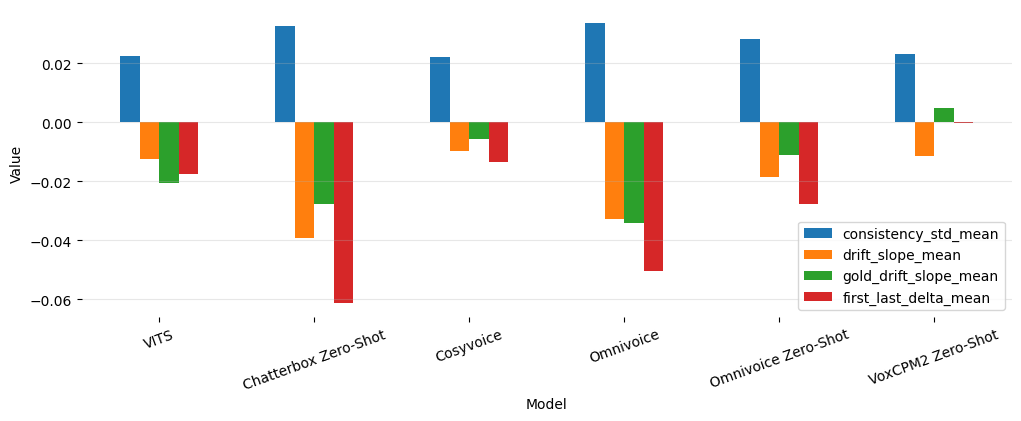

In [7]:
render_temporal_summary_plots(temporal_fixed_all, "fixed")


=== UTMOS_FIXED temporal source: utmos_fixed_w2p0s_h1p0s_partial_model_summary.csv ===


,model_print,mean_utmos_mean,consistency_std_mean,drift_slope_mean,gold_drift_slope_mean,first_last_delta_mean,mean_delta_vs_gold_mean
7,VITS,2.9923,0.2598,0.1175,0.1748,0.1468,0.0462
0,Chatterbox Zero-Shot,3.0258,0.2927,-0.1488,0.1477,-0.3210,0.1068
3,Cosyvoice,3.2762,0.2428,-0.1624,0.1376,-0.2083,0.3337
5,Omnivoice,2.9378,0.2670,0.0567,0.1051,-0.0760,0.0150
6,Omnivoice Zero-Shot,2.9405,0.2719,0.0625,0.1383,0.0903,0.0217
8,VoxCPM2 Zero-Shot,2.7079,0.2884,0.0009,0.1478,0.0389,-0.2157


<Axes: xlabel='Model', ylabel='Value'>

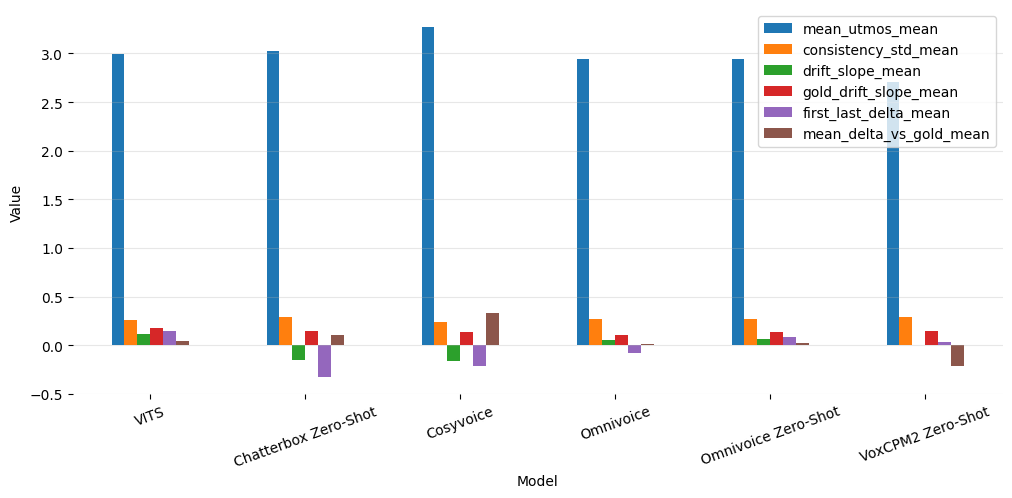

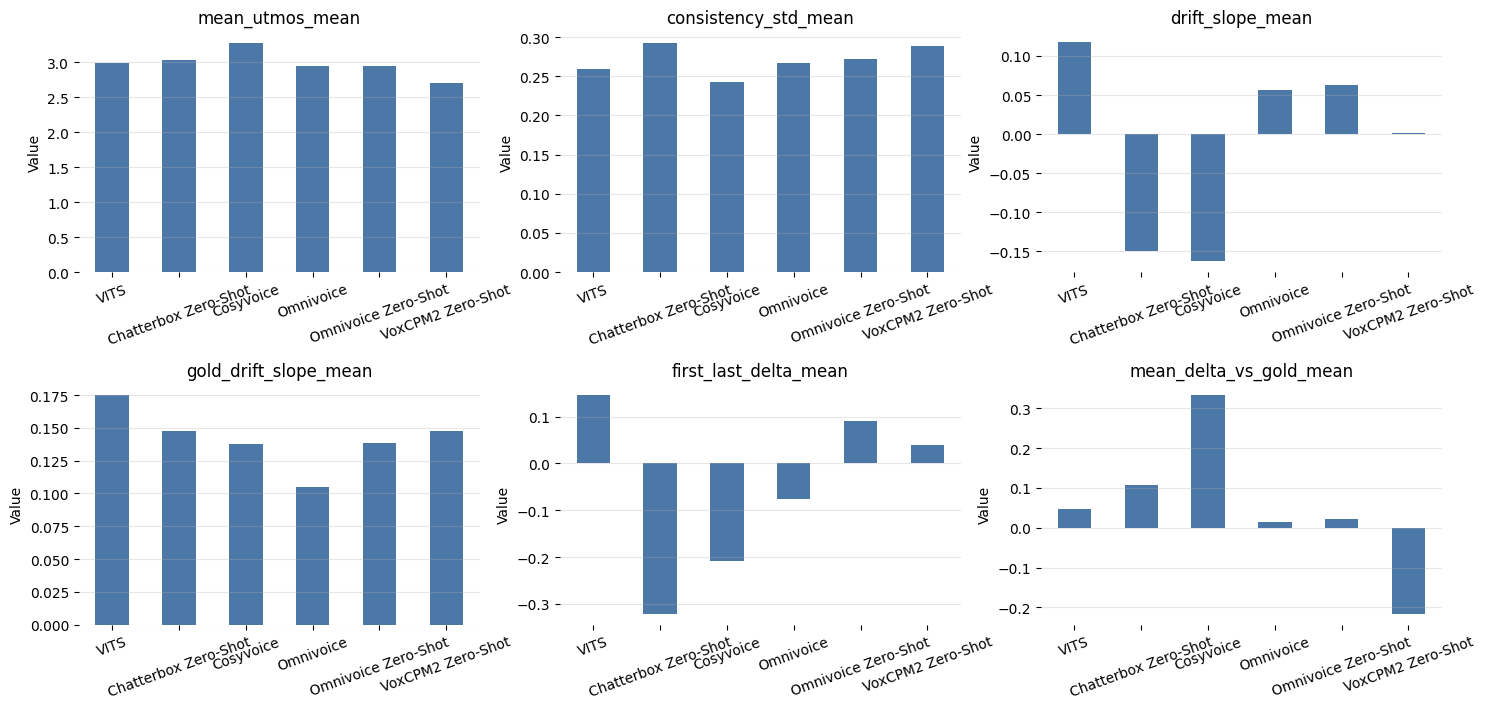

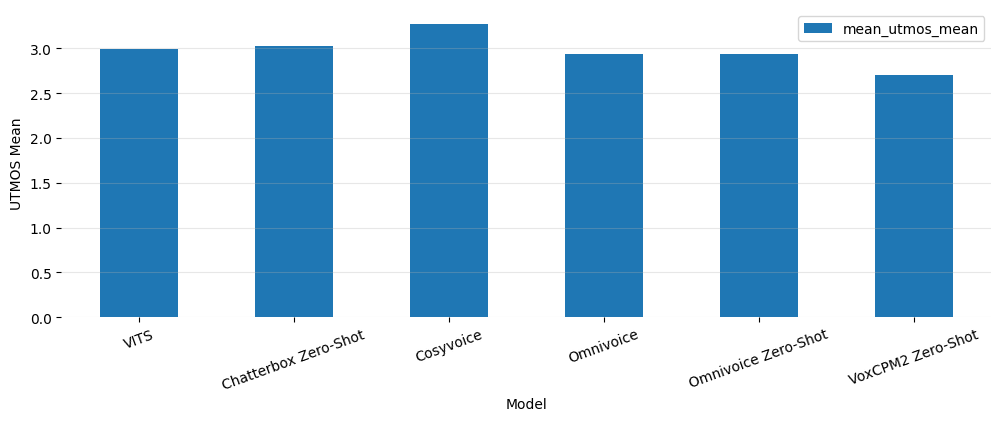

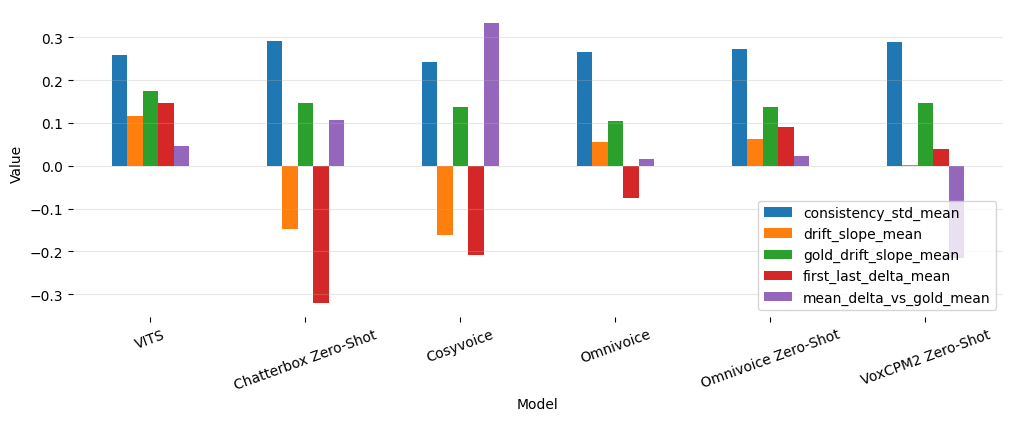

In [8]:
render_temporal_summary_plots(temporal_utmos_fixed_all, "utmos_fixed")


=== PROMINENCE MODEL ORTALAMA ===


,model_print,n,spearman_mean,top1_f1,top2_f1,std_syn,std_gold,wilcoxon_p
0,VITS,274,0.8306,0.5730,0.6405,2.0019,2.0186,0.6496
1,Cosyvoice,274,0.7451,0.5255,0.6058,2.0113,2.0186,0.5142
4,Omnivoice,274,0.7299,0.5255,0.6058,2.0390,2.0186,0.1852
6,VoxCPM2 Zero-Shot,274,0.6623,0.4088,0.5255,2.0036,2.0186,0.2361
7,Chatterbox Zero-Shot,274,0.6511,0.4672,0.5365,2.0204,2.0186,0.1529
8,Omnivoice Zero-Shot,274,0.6447,0.3978,0.5055,2.1165,2.0186,0.0000



=== PROMINENCE LENGTH GROUP OZET ===


,length_group,model_print,n,spearman_mean,top1_f1,top2_f1
7,long,VITS,100,0.8455,0.5600,0.5700
3,long,Cosyvoice,100,0.7269,0.4700,0.5150
5,long,Omnivoice,100,0.7143,0.4700,0.5100
8,long,VoxCPM2 Zero-Shot,100,0.6575,0.3600,0.4600
0,long,Chatterbox Zero-Shot,100,0.6424,0.4000,0.4450
6,long,Omnivoice Zero-Shot,100,0.6035,0.2900,0.4150
17,medium,VITS,100,0.8297,0.4900,0.5900
13,medium,Cosyvoice,100,0.7466,0.4800,0.6050
15,medium,Omnivoice,100,0.7222,0.5000,0.5950
18,medium,VoxCPM2 Zero-Shot,100,0.6589,0.3300,0.4950


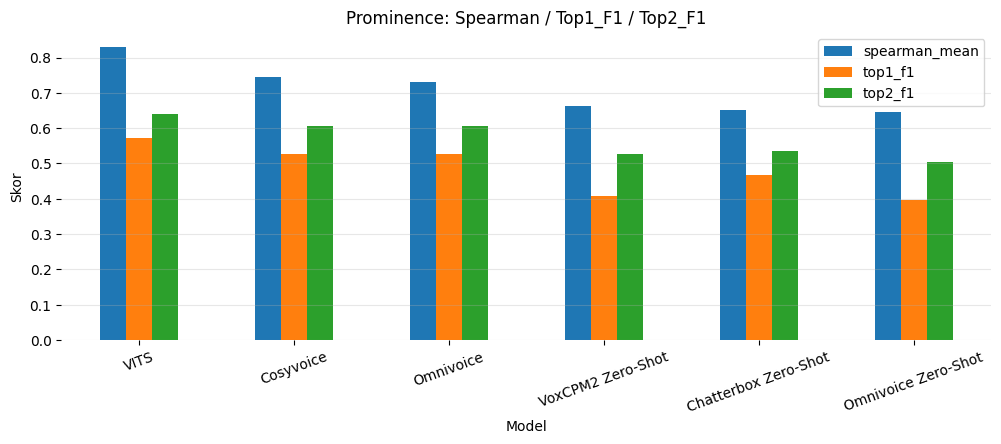

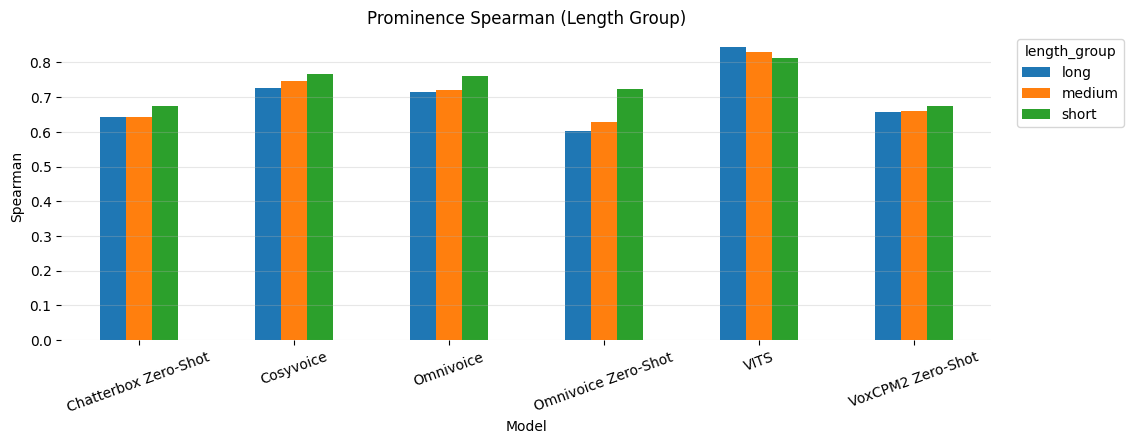

In [9]:
# ---- Prominence sonuclari (yunusemre) ----
prom_avg_path = "/mnt/local3/tts/tts_evaluation/evaluation_tool/yunusemre/results.csv"
prom_len_path = "/mnt/local3/tts/tts_evaluation/evaluation_tool/yunusemre/results_by_length.csv"

if not Path(prom_avg_path).exists():
    print(f"Prominence ortalama dosyasi bulunamadi: {prom_avg_path}")
else:
    prom_avg = pd.read_csv(prom_avg_path)

    if ignore_results:
        prom_avg = prom_avg[~prom_avg["model"].isin(ignore_results)].copy()

    prom_avg["model_print"] = prom_avg["model"].map(map_model_name)
    prom_avg = prom_avg.sort_values("spearman_mean", ascending=False)

    print("\n=== PROMINENCE MODEL ORTALAMA ===")
    display(
        prom_avg[
            [
                "model_print",
                "n",
                "spearman_mean",
                "top1_f1",
                "top2_f1",
                "std_syn",
                "std_gold",
                "wilcoxon_p",
            ]
        ].round(4)
    )

    ax = prom_avg.plot(
        kind="bar",
        x="model_print",
        y=["spearman_mean", "top1_f1", "top2_f1"],
        figsize=(12, 4),
        rot=20,
        title="Prominence: Spearman / Top1_F1 / Top2_F1",
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("Skor")
    ax.grid(True, axis="y", alpha=0.3)
    for spine in ax.spines.values():
        spine.set_visible(False)

if Path(prom_len_path).exists():
    prom_len = pd.read_csv(prom_len_path)

    if ignore_results:
        prom_len = prom_len[~prom_len["model"].isin(ignore_results)].copy()

    prom_len["model_print"] = prom_len["model"].map(map_model_name)

    print("\n=== PROMINENCE LENGTH GROUP OZET ===")
    display(
        prom_len[
            [
                "length_group",
                "model_print",
                "n",
                "spearman_mean",
                "top1_f1",
                "top2_f1",
            ]
        ]
        .sort_values(["length_group", "spearman_mean"], ascending=[True, False])
        .round(4)
    )

    pivot = prom_len.pivot_table(
        index="model_print",
        columns="length_group",
        values="spearman_mean",
        aggfunc="mean",
    )

    ax2 = pivot.plot(kind="bar", figsize=(12, 4), rot=20, title="Prominence Spearman (Length Group)")
    ax2.set_xlabel("Model")
    ax2.set_ylabel("Spearman")
    ax2.grid(True, axis="y", alpha=0.3)
    ax2.legend(title="length_group", bbox_to_anchor=(1.02, 1), loc="upper left")
    for spine in ax2.spines.values():
        spine.set_visible(False)
else:
    print(f"Prominence length-group dosyasi bulunamadi: {prom_len_path}")


=== WER MODEL ORTALAMA (%) ===


,model,wer_pct
4,voxcpm2_zs,67.17
7,omnivoice,67.50
0,gold,67.59
3,chatterbox_zs,67.87
8,omnivoice_raw,68.14
5,vits,68.27
2,omnivoice_zs,68.34
6,cosyvoice_paris,68.76
1,cosyvoice,69.53
9,cosyvoice_raw,69.69


Uyari: 1551 WER satirinda length_group eslesmedi.

=== WER MODEL BAZLI (cümleler art arda birleştirilerek, %) ===


,Input,Input_print,n_sentences,ref_words,hyp_words,concat_wer_pct
9,voxcpm2_zs,voxcpm2_zs,300.0,3180.0,4101.0,65.88
4,gold,gold,300.0,3180.0,4089.0,66.10
6,omnivoice_raw,omnivoice_raw,300.0,3180.0,4105.0,66.10
5,omnivoice,omnivoice,300.0,3180.0,4102.0,66.13
0,chatterbox_zs,chatterbox_zs,299.0,3179.0,4112.0,66.31
7,omnivoice_zs,omnivoice_zs,300.0,3180.0,4097.0,66.98
8,vits,vits,300.0,3180.0,4081.0,67.08
2,cosyvoice_paris,cosyvoice_paris,300.0,3180.0,4094.0,67.20
1,cosyvoice,cosyvoice,300.0,3180.0,4086.0,67.30
3,cosyvoice_raw,cosyvoice_raw,300.0,3180.0,4112.0,68.24



=== WER LENGTH GROUP BAZLI (cümleler art arda birleştirilerek, %) ===


,length_group,Input,Input_print,n_sentences,ref_words,hyp_words,concat_wer_pct
10,long,voxcpm_trendyol,voxcpm_trendyol,1.0,18.0,19.0,11.11
5,long,omnivoice,omnivoice,47.0,736.0,1088.0,89.81
6,long,omnivoice_raw,omnivoice_raw,47.0,736.0,1090.0,89.81
4,long,gold,gold,47.0,736.0,1089.0,90.08
9,long,voxcpm2_zs,voxcpm2_zs,47.0,736.0,1088.0,90.08
0,long,chatterbox_zs,chatterbox_zs,47.0,736.0,1091.0,90.35
7,long,omnivoice_zs,omnivoice_zs,47.0,736.0,1090.0,90.62
3,long,cosyvoice_raw,cosyvoice_raw,47.0,736.0,1089.0,90.90
8,long,vits,vits,47.0,736.0,1084.0,91.17
2,long,cosyvoice_paris,cosyvoice_paris,47.0,736.0,1088.0,91.30



=== WER PIVOT (Input x length_group, %) ===


length_group,long,medium,short
Input_print,,,
chatterbox_zs,90.35,37.10,16.46
cosyvoice,91.58,37.99,19.33
cosyvoice_paris,91.30,39.43,20.17
cosyvoice_raw,90.90,39.25,19.75
gold,90.08,37.46,18.07
omnivoice,89.81,36.92,18.07
omnivoice_raw,89.81,37.10,15.97
omnivoice_zs,90.62,38.53,16.81
vits,91.17,38.53,19.75



-> /mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_v2_wer_v3_concat_model_pct.csv
-> /mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_v2_wer_v3_concat_length_pct.csv


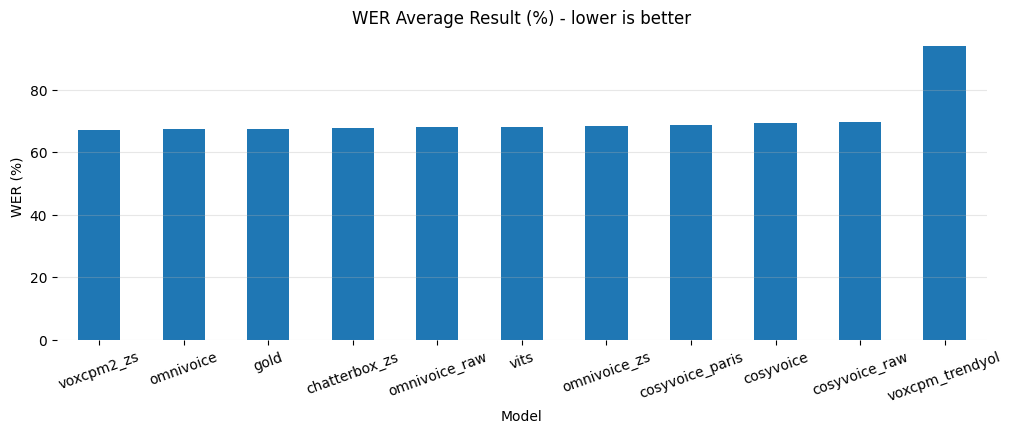

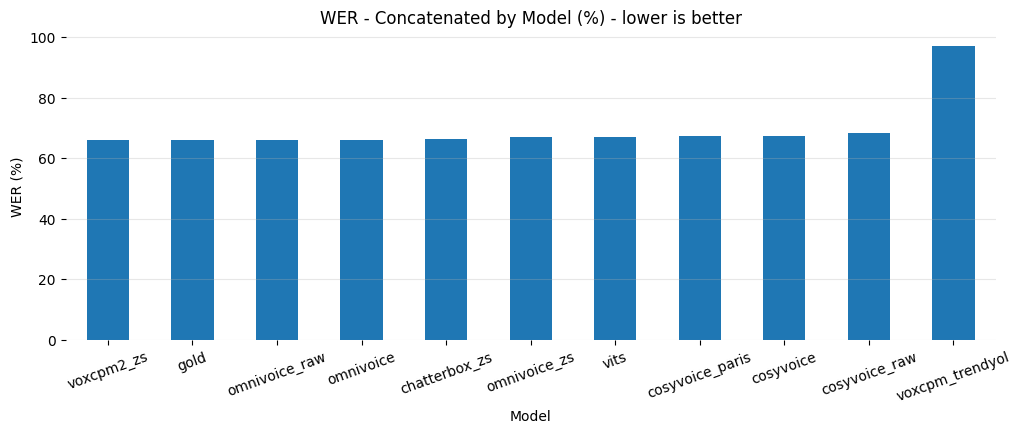

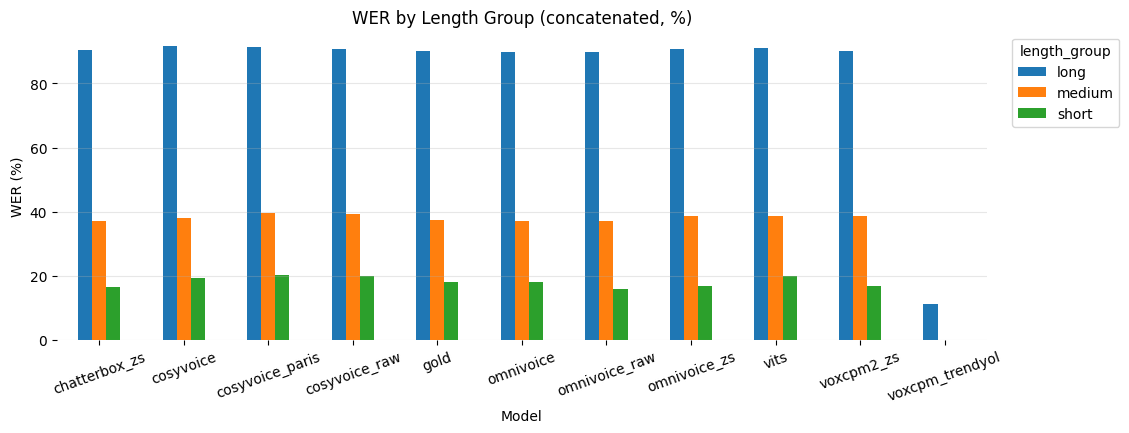

In [7]:
# ---- WER sonuclari (sentences concatenated per model / length_group) ----
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from jiwer import wer

# Notebook disindan tek basina calistirilirse gerekli degiskenleri tumle.
try:
    ignore_results
except NameError:
    ignore_results = []

try:
    map_model_name
except NameError:
    def map_model_name(model_name: str) -> str:
        return model_name

try:
    test_df
except NameError:
    test_df = pd.read_csv("/mnt/local3/tts/tts_evaluation/data/tts_evaluation_test.csv")

wer_avg_path = Path("/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_v2_wer_v3_average.csv")
wer_detail_path = Path("/mnt/local3/tts/tts_evaluation/evaluation_tool/results_tts_evaluation_test_v2_wer_v3_detailed.csv")
wer_test_path = Path("/mnt/local3/tts/tts_evaluation/data/tts_evaluation_test_stress.csv")
wer_test_df = pd.read_csv(wer_test_path) if wer_test_path.exists() else test_df.copy()
wer_scale = 100.0


def _normalize_wer_text(text: str) -> str:
    text = str(text).lower()
    text = text.replace("’", "'")
    text = re.sub(r"[^\w\sçğıöşüâîû']+", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+'\s+", "'", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


if not wer_avg_path.exists():
    print(f"WER average dosyasi bulunamadi: {wer_avg_path}")
else:
    wer_avg = pd.read_csv(wer_avg_path)
    if ignore_results:
        wer_avg = wer_avg[~wer_avg["Input"].isin(ignore_results)].copy()

    wer_avg["Input_print"] = wer_avg["Input"].map(map_model_name)
    wer_avg["Average Result"] = wer_avg["Average Result"] * wer_scale
    wer_avg = wer_avg.sort_values("Average Result", ascending=True)

    print("\n=== WER MODEL ORTALAMA (%) ===")
    display(
        wer_avg[["Input_print", "Average Result"]]
        .rename(columns={"Input_print": "model", "Average Result": "wer_pct"})
        .round(2)
    )

    ax = wer_avg.plot(
        kind="bar",
        x="Input_print",
        y="Average Result",
        figsize=(12, 4),
        rot=20,
        legend=False,
        title="WER Average Result (%) - lower is better",
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("WER (%)")
    ax.grid(True, axis="y", alpha=0.3)
    for spine in ax.spines.values():
        spine.set_visible(False)

if not wer_detail_path.exists():
    print(f"WER detail dosyasi bulunamadi: {wer_detail_path}")
else:
    wer_detail = pd.read_csv(wer_detail_path)
    if ignore_results:
        wer_detail = wer_detail[~wer_detail["Input"].isin(ignore_results)].copy()

    # length_group bilgisini ilgili test CSV'den ekle; esleme v2_ + stem uzerinden yapilir.
    test_len_map = wer_test_df[["id", "length_group"]].copy()
    test_len_map = test_len_map.drop_duplicates(subset=["id"], keep="first")

    wer_detail = wer_detail.copy()
    wer_detail["file_id"] = wer_detail["File"].map(lambda p: f"v2_{Path(str(p)).stem}")
    wer_detail = wer_detail.merge(
        test_len_map,
        left_on="file_id",
        right_on="id",
        how="left",
    )

    if wer_detail["length_group"].isna().any():
        missing = int(wer_detail["length_group"].isna().sum())
        print(f"Uyari: {missing} WER satirinda length_group eslesmedi.")

    wer_detail["Input_print"] = wer_detail["Input"].map(map_model_name)
    wer_detail = wer_detail.sort_values(["Input", "length_group", "file_id"]).reset_index(drop=True)

    def _concat_wer_group(df: pd.DataFrame) -> pd.Series:
        ref = " ".join(df["wer_v3_reference"].fillna("").astype(str).map(_normalize_wer_text).tolist())
        hyp = " ".join(df["wer_v3_hypothesis"].fillna("").astype(str).map(_normalize_wer_text).tolist())
        ref_words = len(ref.split())
        hyp_words = len(hyp.split())
        return pd.Series({
            "n_sentences": len(df),
            "ref_words": ref_words,
            "hyp_words": hyp_words,
            "concat_wer_pct": wer(ref, hyp) * wer_scale,
        })

    wer_by_model_rows = []
    for (inp, inp_print), g in wer_detail.groupby(["Input", "Input_print"], sort=True):
        metrics = _concat_wer_group(g)
        wer_by_model_rows.append({"Input": inp, "Input_print": inp_print, **metrics.to_dict()})
    wer_by_model = pd.DataFrame(wer_by_model_rows).sort_values("concat_wer_pct", ascending=True)

    print("\n=== WER MODEL BAZLI (cümleler art arda birleştirilerek, %) ===")
    display(wer_by_model.round(2))

    ax2 = wer_by_model.plot(
        kind="bar",
        x="Input_print",
        y="concat_wer_pct",
        figsize=(12, 4),
        rot=20,
        legend=False,
        title="WER - Concatenated by Model (%) - lower is better",
    )
    ax2.set_xlabel("Model")
    ax2.set_ylabel("WER (%)")
    ax2.grid(True, axis="y", alpha=0.3)
    for spine in ax2.spines.values():
        spine.set_visible(False)

    wer_by_length_rows = []
    for (lg, inp, inp_print), g in wer_detail.groupby(["length_group", "Input", "Input_print"], sort=True):
        metrics = _concat_wer_group(g)
        wer_by_length_rows.append({"length_group": lg, "Input": inp, "Input_print": inp_print, **metrics.to_dict()})
    wer_by_length = pd.DataFrame(wer_by_length_rows).sort_values(["length_group", "concat_wer_pct"], ascending=[True, True])

    print("\n=== WER LENGTH GROUP BAZLI (cümleler art arda birleştirilerek, %) ===")
    display(wer_by_length.round(2))

    wer_pivot = wer_by_length.pivot_table(
        index="Input_print",
        columns="length_group",
        values="concat_wer_pct",
        aggfunc="mean",
    )
    print("\n=== WER PIVOT (Input x length_group, %) ===")
    display(wer_pivot.round(2))

    ax3 = wer_pivot.plot(
        kind="bar",
        figsize=(12, 4),
        rot=20,
        title="WER by Length Group (concatenated, %)",
    )
    ax3.set_xlabel("Model")
    ax3.set_ylabel("WER (%)")
    ax3.grid(True, axis="y", alpha=0.3)
    ax3.legend(title="length_group", bbox_to_anchor=(1.02, 1), loc="upper left")
    for spine in ax3.spines.values():
        spine.set_visible(False)

    out_model_path = wer_avg_path.with_name("results_tts_evaluation_test_v2_wer_v3_concat_model_pct.csv")
    out_length_path = wer_avg_path.with_name("results_tts_evaluation_test_v2_wer_v3_concat_length_pct.csv")
    wer_by_model.to_csv(out_model_path, index=False)
    wer_by_length.to_csv(out_length_path, index=False)
    print(f"\n-> {out_model_path}")
    print(f"-> {out_length_path}")